In [1]:
import pandas as pd

In [2]:
# Cargamos los datos

data = pd.read_csv("processed_dataset.csv", low_memory=False)

In [3]:
data.subreddit

0         analytics
1         analytics
2         analytics
3         analytics
4         analytics
            ...    
274234       rstats
274235       rstats
274236       rstats
274237       rstats
274238       rstats
Name: subreddit, Length: 274239, dtype: object

In [4]:
# Cantidad de valores faltantes

data.subreddit.isna().sum()

30

In [5]:
# Limpieza de datos

data = data.dropna(subset=["clean_post", "subreddit"])   # Eliminar valores faltantes
data["subreddit"] = data["subreddit"].astype("category")   # Convertir etiquetas a categóricas

In [ ]:
data.subreddit.unique()

### Método TF-IDF

F1 Score: 0.4091239105468032
              precision    recall  f1-score   support

           0       0.43      0.66      0.52      8959
           1       0.98      0.47      0.64       703
           2       0.04      0.00      0.01      3475
           3       0.31      0.71      0.43     11122
           4       0.89      0.43      0.58      2349
           5       0.52      0.15      0.23      2608
           6       0.70      0.53      0.60      6773
           7       0.69      0.26      0.37      2880
           8       0.90      0.22      0.36       838
           9       0.25      0.01      0.01      1194
          10       0.84      0.33      0.47      2446
          11       0.43      0.68      0.53     11170
          12       0.12      0.01      0.02        73
          13       0.70      0.35      0.47      3441
          14       0.09      0.01      0.02      2430
          15       0.00      0.00      0.00       126
          16       0.41      0.28      0.33      879

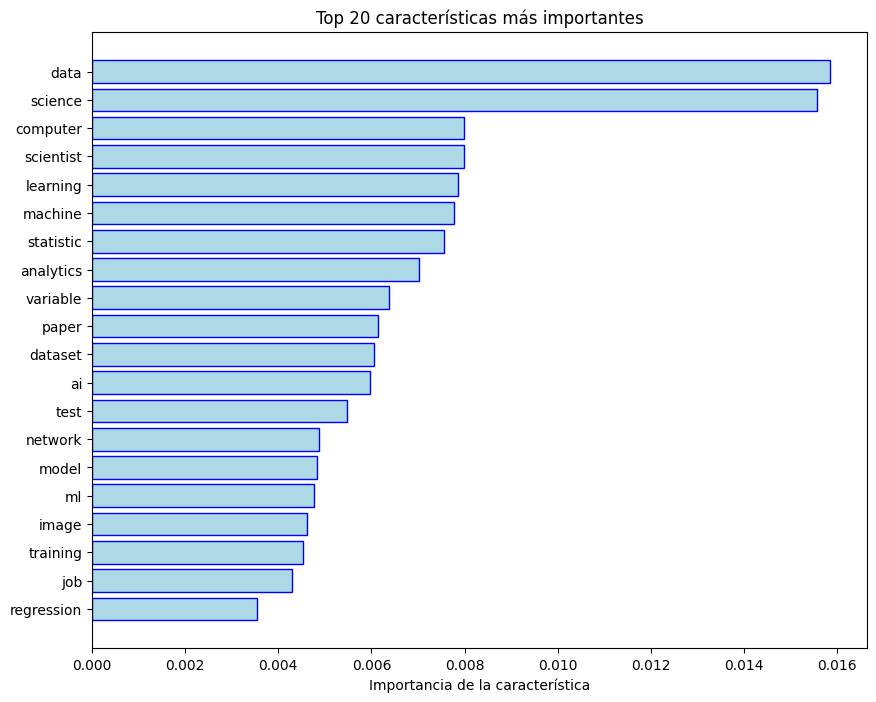

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report
from sklearn.preprocessing import LabelEncoder
import numpy as np
import matplotlib.pyplot as plt


# 1. División de datos en entrenamiento y prueba (70% - 30%)
X_train, X_test, y_train, y_test = train_test_split(data["clean_post"], data["subreddit"], test_size=0.3, random_state=42)

# 2. Vectorización TF-IDF
# Convierte los textos en matrices numéricas donde cada valor representa la importancia relativa de cada término en el documento
vectorizer_tfidf = TfidfVectorizer(max_df=0.95, min_df=5)
X_train_tfidf = vectorizer_tfidf.fit_transform(X_train)
X_test_tfidf = vectorizer_tfidf.transform(X_test)

# 3. Codificar las etiquetas
# Convierte las etiquetas categóricas en valores numéricos
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# 4. Entrenamiento del modelo
# Se utiliza un clasificador Random Forest, que combina múltiples árboles de decisión
classifier = RandomForestClassifier(random_state=42, n_estimators=100, n_jobs=-1, bootstrap=True, max_depth=50, min_samples_leaf=1, min_samples_split=2, max_features="sqrt")
classifier.fit(X_train_tfidf, y_train_encoded)

# 5. Predicción y evaluación
y_pred = classifier.predict(X_test_tfidf)
f1 = f1_score(y_test_encoded, y_pred, average="weighted")
print(f"F1 Score: {f1}")
print(classification_report(y_test_encoded, y_pred, zero_division=0))


# Obtener la importancia de las características del clasificador
feature_importances = classifier.feature_importances_

# Obtener los nombres de las características
feature_names = vectorizer_tfidf.get_feature_names_out()

# Ordenar las características por importancia
sorted_indices = np.argsort(feature_importances)[::-1]

# Seleccionar las 20 características más importantes
top_n = 20
top_features = [feature_names[i] for i in sorted_indices[:top_n]]
top_importances = feature_importances[sorted_indices[:top_n]]

# Graficar la importancia de las características
plt.figure(figsize=(10, 8))
plt.barh(top_features, top_importances, color="lightblue", align="center", edgecolor="blue")
plt.xlabel("Importancia de la característica")
plt.title("Top 20 características más importantes")
plt.gca().invert_yaxis()
plt.show()

In [7]:
def classify_subreddit_1(text):
    '''Función para clasificar un texto de entrada en un subreddit predefinido.'''

    # 1. Preprocesar y vectorizar el texto
    # Convierte el texto de entrada en una representación numérica utilizando
    # el vectorizador TF-IDF ajustado durante el entrenamiento.
    text_vectorized = vectorizer_tfidf.transform([text])
    
    # 2. Realizar predicción
    # Utiliza el modelo de clasificación entrenado para predecir la etiqueta del texto.
    prediction = classifier.predict(text_vectorized)
    
    # 3. Decodificar la etiqueta predicha
    # Convierte la predicción numérica de vuelta a la etiqueta categórica original.
    subreddit = label_encoder.inverse_transform(prediction)

    return subreddit[0]


# Ejemplo
text = "Amo trabajar en proyectos de Machine Learning con Python."
print(classify_subreddit_1(text))

learnmachinelearning


##### Exploración básica de hiperparámetros

In [8]:
# from sklearn.ensemble import RandomForestRegressor
# from sklearn.model_selection import GridSearchCV

# model = RandomForestRegressor(random_state=42)

# # Parámetros básicos a probar
# param_grid = {
#     "n_estimators": [100, 200, 300],
#     "max_depth": [None, 10, 20],
#     "min_samples_split": [2, 5],
# }

# # GridSearchCV para encontrar los mejores parámetros
# grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, n_jobs=-1, verbose=2)
# grid_search.fit(X_train_tfidf, y_train_encoded)

# # Mostrar los mejores parámetros encontrados
# print("Mejores parámetros básicos:", grid_search.best_params_)

##### Ajuste detallado del número de estimadores

In [9]:
# param_grid = {
#     "n_estimators": [50, 100, 150, 200, 250, 300, 400, 500],
#     "max_depth": [None, 20],
# }

# grid_search = GridSearchCV(estimator=RandomForestRegressor(random_state=42), param_grid=param_grid, cv=5, n_jobs=-1, verbose=2)
# grid_search.fit(X_train_tfidf, y_train_encoded)

# print("Mejores parámetros (n_estimators ajustado):", grid_search.best_params_)

##### Exploración avanzada del tamaño de hojas y divisiones mínimas

In [10]:
# param_grid = {
#     "min_samples_split": [2, 5, 10, 15],
#     "min_samples_leaf": [1, 2, 4, 6],
#     "max_depth": [None, 20],
# }

# grid_search = GridSearchCV(estimator=RandomForestRegressor(random_state=42), param_grid=param_grid, cv=5, n_jobs=-1, verbose=2)
# grid_search.fit(X_train_tfidf, y_train_encoded)

# print("Mejores parámetros (tamaño de hojas y divisiones):", grid_search.best_params_)

##### Configuración con bootstrap y criterio de división

In [11]:
# param_grid = {
#     "bootstrap": [True, False],
#     "criterion": ["squared_error", "absolute_error"],
#     "n_estimators": [100, 200],
# }

# grid_search = GridSearchCV(estimator=RandomForestRegressor(random_state=42), param_grid=param_grid, cv=5, n_jobs=-1, verbose=2)
# grid_search.fit(X_train_tfidf, y_train_encoded)

# print("Mejores parámetros (bootstrap y criterio):", grid_search.best_params_)

##### Combinación completa (exploración detallada)

In [12]:
# param_grid = {
#     "n_estimators": [100, 200, 300],
#     "max_depth": [None, 10, 20],
#     "min_samples_split": [2, 5, 10],
#     "min_samples_leaf": [1, 2, 4],
#     "bootstrap": [True, False],
# }

# grid_search = GridSearchCV(estimator=RandomForestRegressor(random_state=42), param_grid=param_grid, cv=5, n_jobs=-1, verbose=2)
# grid_search.fit(X_train_tfidf, y_train_encoded)

# print("Mejores parámetros (combinación completa):", grid_search.best_params_)

##### Exploración de criterios de división más específicos

In [13]:
# param_grid = {
#     "criterion": ["squared_error", "absolute_error", "poisson"],
#     "max_features": ["sqrt", "log2"],
#     "n_estimators": [100, 300],
# }

# grid_search = GridSearchCV(estimator=RandomForestRegressor(random_state=42), param_grid=param_grid, cv=5, n_jobs=-1, verbose=2)
# grid_search.fit(X_train_tfidf, y_train_encoded)

# print("Mejores parámetros (criterios específicos):", grid_search.best_params_)

### Método Named-Entity Recognition

In [14]:
import re
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer

# Cargar las stopwords en inglés de NLTK
stop_words = stopwords.words("english")


def extract_named_entities(text):
    """
    Extrae entidades nombradas de un texto dado basado en patrones predefinidos.
    
    - technical_terms: Palabras en CamelCase.
    - abbreviations: Palabras completamente en mayúsculas.
    - code_elements: Palabras en camelCase.
    """
    # Patrones para encontrar diferentes tipos de entidades
    patterns = {
        "technical_terms": r"\b(?:[A-Z][a-z]+){2,}\b",  
        "abbreviations": r"\b[A-Z]{2,}\b",              
        "code_elements": r"\b[a-z]+[A-Z][a-zA-Z]*\b"    
    }
    
    # Se almacenan las entidades encontradas en el texto
    entities = []
    for _, pattern in patterns.items():
        found_entities = re.findall(pattern, text)   
        entities.extend(found_entities)   
    
    # Filtramos las entidades eliminando stopwords y términos demasiado cortos
    filtered_entities = [entity for entity in entities if len(entity) > 2 and entity.lower() not in stop_words]
    
    # Devuelve las entidades concatenadas como un solo string
    return " ".join(filtered_entities) if filtered_entities else "no_entities"


# 1. Agregar una nueva columna 'named_entities' al DataFrame con las entidades extraídas
data["named_entities"] = data["clean_post"].apply(extract_named_entities)

# 2. División de datos en entrenamiento y prueba (70% - 30%)
X_train, X_test, y_train, y_test = train_test_split(data["named_entities"], data["subreddit"], test_size=0.3, random_state=42)

# 3. Vectorización de las entidades nombradas
vectorizer = CountVectorizer()
X_train_entities = vectorizer.fit_transform(X_train)
X_test_entities = vectorizer.transform(X_test)        

# 4. Codificación de etiquetas
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)  
y_test_encoded = label_encoder.transform(y_test)       

# 4. Entrenamiento del modelo
classifier = RandomForestClassifier(random_state=42, n_estimators=1000, n_jobs=-1, bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2)
classifier.fit(X_train_entities, y_train_encoded)

# 5. Predicción y evaluación
y_pred = classifier.predict(X_test_entities)
f1 = f1_score(y_test_encoded, y_pred, average="weighted")
print(f"F1 Score: {f1}")
# print(classification_report(y_test_encoded, y_pred, zero_division=0))

F1 Score: 0.032909301435714466


In [15]:
def classify_subreddit_2(text):
    """Clasifica un texto de entrada en una categoría de subreddit basándose en entidades nombradas extraídas."""
    
    # 1. Preprocesar el texto y extraer las entidades relevantes
    # Extrae términos significativos del texto utilizando un método optimizado de extracción de entidades.
    named_entities = extract_named_entities(text)
    
    # 2. Vectorizar el texto de entrada
    # Convierte las entidades extraídas en una representación numérica adecuada para el clasificador.
    text_vectorized = vectorizer.transform([named_entities])
    
    # 3. Realizar la predicción
    # Utiliza el modelo entrenado para determinar la categoría del texto.
    prediction = classifier.predict(text_vectorized)
    
    # 4. Decodificar la clase de la predicción
    # Traduce la predicción numérica del modelo a la etiqueta categórica original.
    subreddit = label_encoder.inverse_transform(prediction)
    
    return subreddit[0]

# Ejemplo
text = "Amo trabajar en proyectos de Machine Learning con Python."
print(classify_subreddit_2(text))

datascience


In [16]:
import spacy

# Cargar el modelo de spaCy para el reconocimiento de entidades nombradas
nlp = spacy.load("en_core_web_sm")


def extract_named_entities(text):
    # Procesar el texto con spaCy
    doc = nlp(text)
    
    # Filtrar las entidades relevantes
    entities = [ent.text for ent in doc.ents if ent.label_ in ["ORG", "GPE", "PERSON", "PRODUCT", "DATE", "TIME", "MONEY", "LOC"]]
    
    # Concatenar las entidades en un solo string
    return " ".join(entities)


# 1. Tomar una muestra del 10% de los datos
sample_data = data.sample(frac=0.1, random_state=42)

# 2. Crear una serie con las entidades extraídas
named_entities = sample_data["clean_post"].apply(extract_named_entities)

# 3. División de datos en entrenamiento y prueba (70% - 30%)
X_train, X_test, y_train, y_test = train_test_split(named_entities, sample_data["subreddit"], test_size=0.3, random_state=42)

# 4. Vectorización de las entidades nombradas
vectorizer = CountVectorizer()
X_train_entities = vectorizer.fit_transform(X_train)
X_test_entities = vectorizer.transform(X_test)        

# 5. Codificación de etiquetas
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)  
y_test_encoded = label_encoder.transform(y_test)       

# 6. Entrenamiento del modelo
classifier = RandomForestClassifier(random_state=42, n_estimators=1000, n_jobs=-1, bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2)
classifier.fit(X_train_entities, y_train_encoded)

# 7. Predicción y evaluación
y_pred = classifier.predict(X_test_entities)
f1 = f1_score(y_test_encoded, y_pred, average="weighted")
print(f"F1 Score: {f1}")
# print(classification_report(y_test_encoded, y_pred, zero_division=0))

F1 Score: 0.14965309682221248


##### Prueba con spaCy

In [21]:
# Ejemplo
text = "Proyectos de Machine Learning con Python."
print(extract_named_entities(text))

Proyectos de Machine Learning


##### Prueba con Stanza

In [ ]:
import stanza

# Descargar el modelo de NER de Stanza
# stanza.download("en")

# Cargar el modelo
nlp_stanza = stanza.Pipeline("en")

def extract_named_entities_stanza(text):
    # Procesar el texto con Stanza
    doc = nlp_stanza(text)
    
    # Filtrar entidades relevantes
    entities = [ent.text for ent in doc.ents if ent.type in ["ORG", "GPE", "PERSON", "PRODUCT", "DATE", "TIME", "MONEY"]]
    
    return " ".join(entities)

# Ejemplo
text = "Proyectos de Machine Learning con Python."
print(extract_named_entities_stanza(text))

2024-12-16 08:53:31 INFO: Checking for updates to resources.json in case models have been updated.  Note: this behavior can be turned off with download_method=None or download_method=DownloadMethod.REUSE_RESOURCES


2024-12-16 08:53:31 INFO: Downloaded file to C:\Users\Usuario\stanza_resources\resources.json
2024-12-16 08:53:32 INFO: Loading these models for language: en (English):
| Processor    | Package                   |
--------------------------------------------
| tokenize     | combined                  |
| mwt          | combined                  |
| pos          | combined_charlm           |
| lemma        | combined_nocharlm         |
| constituency | ptb3-revised_charlm       |
| depparse     | combined_charlm           |
| sentiment    | sstplus_charlm            |
| ner          | ontonotes-ww-multi_charlm |

2024-12-16 08:53:32 INFO: Using device: cpu
2024-12-16 08:53:32 INFO: Loading: tokenize
c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\stanza\models\tokenization\trainer.py:82: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct m

### Método Word Embeddings

In [19]:
import torch
from transformers import DistilBertTokenizer, DistilBertModel
from tqdm import tqdm


# 1. Cargar el modelo DistilBERT y el tokenizador
model_name = "distilbert-base-uncased"
tokenizer = DistilBertTokenizer.from_pretrained(model_name)
model = DistilBertModel.from_pretrained(model_name)

def text_to_embedding(text, tokenizer, model):
    # Tokenizar el texto
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=512)
    
    # Generar embeddings sin calcular los gradientes
    with torch.no_grad():
        outputs = model(**inputs)
    
    # Promediar las representaciones de los tokens
    return outputs.last_hidden_state.mean(dim=1).squeeze().detach().numpy()


# 2. Se toma una muestra del 5% de los datos
sample_data = data.sample(frac=0.05, random_state=42)

# 3. Dividir datos en entrenamiento y prueba (70% - 30%)
X_train, X_test, y_train, y_test = train_test_split(sample_data["clean_post"], sample_data["subreddit"], test_size=0.3, random_state=42)

# 4. Entrenar el label_encoder con todas las etiquetas posibles
label_encoder = LabelEncoder()
label_encoder.fit(sample_data["subreddit"])

# 5. Transformar las etiquetas de entrenamiento y prueba
y_train_encoded = label_encoder.transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# 6. Generar embeddings para los textos de entrenamiento y prueba con barra de progreso
X_train_embeddings = np.array([text_to_embedding(text, tokenizer, model) for text in tqdm(X_train, desc="Generating train embeddings")])
X_test_embeddings = np.array([text_to_embedding(text, tokenizer, model) for text in tqdm(X_test, desc="Generating test embeddings")])

# 7. Entrenamiento del clasificador con parámetros optimizados
classifier = RandomForestClassifier(random_state=42, n_estimators=50, n_jobs=-1, max_depth=50, min_samples_leaf=1, min_samples_split=2, max_features="sqrt")
classifier.fit(X_train_embeddings, y_train_encoded)

# 8. Predicción y evaluación
y_pred = classifier.predict(X_test_embeddings)
f1 = f1_score(y_test_encoded, y_pred, average="weighted")
print(f"F1 Score: {f1}")
# print(classification_report(y_test_encoded, y_pred, target_names=label_encoder.classes_))

Generating test embeddings: 100%|██████████| 4084/4084 [02:29<00:00, 27.23it/s]


F1 Score: 0.29498637020557866


In [20]:
def classify_subreddit_3(text):
    """Clasifica un texto de entrada en una categoría de subreddit utilizando embeddings de DistilBERT."""
    
    # Convertir el texto a embeddings utilizando DistilBERT
    text_embedding = text_to_embedding(text, tokenizer, model)
    
    # Realizar la predicción utilizando el clasificador entrenado
    prediction = classifier.predict(np.array([text_embedding for text in X_train]))
    
    # Decodificar la clase de la predicción
    subreddit = label_encoder.inverse_transform(prediction)
    
    return subreddit[0]

# Ejemplo
text = "Amo trabajar en proyectos de Machine Learning con Python."
print(classify_subreddit_3(text))

MachineLearning
